# PPE Safety Detection — Dataset Analysis

**Purpose:** Inspect the downloaded PPE dataset before any model training.  
**Important:** This notebook does **not** train a model or modify/delete dataset files.

Expected project layout:
```text
PPE_Safety_Detection/
├── data/
│   └── raw/
│       └── ppe_dataset/
│           ├── data.yaml
│           ├── train/images/
│           ├── train/labels/
│           ├── valid/images/
│           └── valid/labels/
└── notebooks/
    └── ppe_dataset_analysis.ipynb
```

Run cells from top to bottom. If a package is missing, install it in the same Python environment used by Jupyter.

## 1. Imports and dataset path

In [29]:
from pathlib import Path
from collections import Counter
import random
import math

import yaml
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

PROJECT_ROOT = Path.cwd()
# If this notebook was opened from the notebooks folder, move up to project root.
if not (PROJECT_ROOT / "data" / "raw" / "ppe_dataset").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_ROOT = PROJECT_ROOT / "data" / "raw" / "ppe_dataset"
print("Project root:", PROJECT_ROOT.resolve())
print("Dataset root:", DATASET_ROOT.resolve())
print("Dataset folder exists:", DATASET_ROOT.exists())

if not DATASET_ROOT.exists():
    raise FileNotFoundError(
        "Dataset folder not found. Expected data/raw/ppe_dataset from the project root."
    )

Project root: C:\Users\morab\Desktop\PPE_Safety_Detection
Dataset root: C:\Users\morab\Desktop\PPE_Safety_Detection\data\raw\ppe_dataset
Dataset folder exists: True


## 2. Read dataset configuration

In [30]:
yaml_path = DATASET_ROOT / "data.yaml"
with yaml_path.open("r", encoding="utf-8-sig") as f:
    config = yaml.safe_load(f)

print(config)
class_names_raw = config.get("names", {})
if isinstance(class_names_raw, list):
    CLASS_NAMES = {i: str(name) for i, name in enumerate(class_names_raw)}
else:
    CLASS_NAMES = {int(k): str(v) for k, v in class_names_raw.items()}

print("\nClasses:")
for class_id, name in sorted(CLASS_NAMES.items()):
    print(f"  {class_id}: {name}")

print("\nNote: this dataset currently defines only the classes listed above.")

{'path': './data/raw/ppe_dataset', 'train': 'train/images', 'val': 'valid/images', 'nc': 4, 'names': {0: 'Helmet', 1: 'NoHelmet', 2: 'NoVest', 3: 'Vest'}}

Classes:
  0: Helmet
  1: NoHelmet
  2: NoVest
  3: Vest

Note: this dataset currently defines only the classes listed above.


## 3. Count images and label files

In [31]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def list_images(folder):
    return sorted(
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ) if folder.exists() else []

summary_rows = []
split_files = {}

for split in ["train", "valid", "test"]:
    image_dir = DATASET_ROOT / split / "images"
    label_dir = DATASET_ROOT / split / "labels"
    images = list_images(image_dir)
    labels = sorted(label_dir.glob("*.txt")) if label_dir.exists() else []
    split_files[split] = {"images": images, "labels": labels, "label_dir": label_dir}

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}
    summary_rows.append({
        "split": split,
        "images": len(images),
        "label_files": len(labels),
        "images_without_label_file": len(image_stems - label_stems),
        "label_files_without_image": len(label_stems - image_stems),
    })

counts_df = pd.DataFrame(summary_rows)
display(counts_df)

,split,images,label_files,images_without_label_file,label_files_without_image
0,train,1829,1829,0,0
1,valid,457,457,0,0
2,test,0,0,0,0


## 4. Check YOLO annotation validity and class balance

In [32]:

# 4. Check YOLO annotation validity and class balance

annotation_rows = []
invalid_rows = []
empty_label_files = []
box_records = []

# Small tolerance for floating-point rounding
tolerance = 1e-4

for split in ["train", "valid", "test"]:
    label_dir = split_files[split]["label_dir"]

    if not label_dir.exists():
        continue

    for label_file in split_files[split]["labels"]:
        lines = label_file.read_text(
            encoding="utf-8-sig"
        ).splitlines()

        # Check whether the label file is empty
        if not any(line.strip() for line in lines):
            empty_label_files.append({
                "split": split,
                "file": label_file.name
            })
            continue

        for line_number, line in enumerate(lines, start=1):
            if not line.strip():
                continue

            parts = line.split()

            try:
                # YOLO format must contain 5 values
                if len(parts) != 5:
                    raise ValueError(
                        f"Expected 5 values, got {len(parts)}"
                    )

                class_id = int(parts[0])
                x_center, y_center, width, height = map(
                    float, parts[1:]
                )

                # Validate class ID
                if class_id not in CLASS_NAMES:
                    raise ValueError(
                        f"Unknown class ID: {class_id}"
                    )

                values = [
                    x_center, y_center, width, height
                ]

                # Check invalid numeric values
                if not all(math.isfinite(v) for v in values):
                    raise ValueError("Non-finite coordinate")

                # Check normalized YOLO coordinates
                if not all(0 <= v <= 1 for v in values):
                    raise ValueError(
                        "Coordinate outside 0..1"
                    )

                if width <= 0 or height <= 0:
                    raise ValueError(
                        "Width and height must be > 0"
                    )

                # Convert center coordinates to box boundaries
                x1 = x_center - width / 2
                x2 = x_center + width / 2
                y1 = y_center - height / 2
                y2 = y_center + height / 2

                # Check image width with tolerance
                if (
                    x1 < -tolerance
                    or x2 > 1 + tolerance
                ):
                    raise ValueError(
                        "Bounding box exceeds image width"
                    )

                # Check image height with tolerance
                if (
                    y1 < -tolerance
                    or y2 > 1 + tolerance
                ):
                    raise ValueError(
                        "Bounding box exceeds image height"
                    )

                # Save valid annotations
                annotation_rows.append({
                    "split": split,
                    "label_file": label_file.name,
                    "class_id": class_id,
                    "class_name": CLASS_NAMES[class_id]
                })

                box_records.append({
                    "split": split,
                    "label_file": label_file.name,
                    "class_id": class_id,
                    "class_name": CLASS_NAMES[class_id],
                    "x_center": x_center,
                    "y_center": y_center,
                    "width": width,
                    "height": height
                })

            except (ValueError, OverflowError) as exc:
                invalid_rows.append({
                    "split": split,
                    "file": label_file.name,
                    "line": line_number,
                    "problem": str(exc),
                    "content": line
                })

# Create DataFrames
annotations_df = pd.DataFrame(annotation_rows)
boxes_df = pd.DataFrame(box_records)
invalid_df = pd.DataFrame(invalid_rows)
empty_df = pd.DataFrame(empty_label_files)

# Display validation results
print("Valid bounding boxes:", len(annotations_df))
print("Invalid annotation rows:", len(invalid_df))
print("Empty label files:", len(empty_df))

if not invalid_df.empty:
    display(invalid_df.head(20))
else:
    print("No invalid annotation rows found.")

if not empty_df.empty:
    display(empty_df.head(20))
else:
    print("No empty label files found.")

# Count valid bounding boxes by class
if not annotations_df.empty:
    class_counts = (
        annotations_df
        .groupby(["split", "class_id", "class_name"])
        .size()
        .reset_index(name="bounding_boxes")
    )
else:
    class_counts = pd.DataFrame(
        columns=[
            "split", "class_id",
            "class_name", "bounding_boxes"
        ]
    )

display(class_counts)


Valid bounding boxes: 6038
Invalid annotation rows: 0
Empty label files: 0
No invalid annotation rows found.
No empty label files found.


,split,class_id,class_name,bounding_boxes
0,train,0,Helmet,1970
1,train,1,NoHelmet,960
2,train,2,NoVest,836
3,train,3,Vest,1096
4,valid,0,Helmet,451
5,valid,1,NoHelmet,214
6,valid,2,NoVest,222
7,valid,3,Vest,289


In [33]:

# 5. Save the updated annotation validation report

print("Invalid annotation rows:", len(invalid_df))

if invalid_df.empty:
    print("No invalid annotation rows found with the current tolerance.")
else:
    display(
        invalid_df.groupby(["split", "problem"])
        .size()
        .reset_index(name="count")
    )
    display(invalid_df.head(20))

report_path = (
    PROJECT_ROOT / "data" / "raw" /
    "invalid_annotations_report.csv"
)

invalid_df.to_csv(report_path, index=False)

print("Report saved to:", report_path)


Invalid annotation rows: 0
No invalid annotation rows found with the current tolerance.
Report saved to: c:\Users\morab\Desktop\PPE_Safety_Detection\data\raw\invalid_annotations_report.csv


In [34]:

from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

# Inspect the first 6 invalid annotation rows
for _, row in invalid_df.head(6).iterrows():
    split = row["split"]
    label_file = row["file"]

    image_path = (
        DATASET_ROOT / split / "images" /
        (Path(label_file).stem + ".jpg")
    )

    # Try other common image extensions if needed
    if not image_path.exists():
        matches = [
            p for p in (DATASET_ROOT / split / "images").glob(
                Path(label_file).stem + ".*"
            )
        ]
        if not matches:
            print("Image not found:", label_file)
            continue
        image_path = matches[0]

    image = Image.open(image_path).convert("RGB")
    w, h = image.size

    fig, ax = plt.subplots(figsize=(9, 6))
    ax.imshow(image)

    label_path = DATASET_ROOT / split / "labels" / label_file
    for line in label_path.read_text(encoding="utf-8-sig").splitlines():
        parts = line.split()
        if len(parts) != 5:
            continue

        class_id = int(parts[0])
        xc, yc, bw, bh = map(float, parts[1:])

        x1 = (xc - bw / 2) * w
        y1 = (yc - bh / 2) * h
        x2 = (xc + bw / 2) * w
        y2 = (yc + bh / 2) * h

        # Red rectangle: may extend beyond image boundaries
        rect = Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False, edgecolor="red", linewidth=2
        )
        ax.add_patch(rect)

        name = CLASS_NAMES.get(class_id, str(class_id))
        ax.text(x1, max(0, y1), name, color="yellow",
                bbox={"facecolor": "black", "alpha": 0.6})

    ax.set_title(f"{split}: {image_path.name}")
    plt.show()


## 5. Visualize class distribution

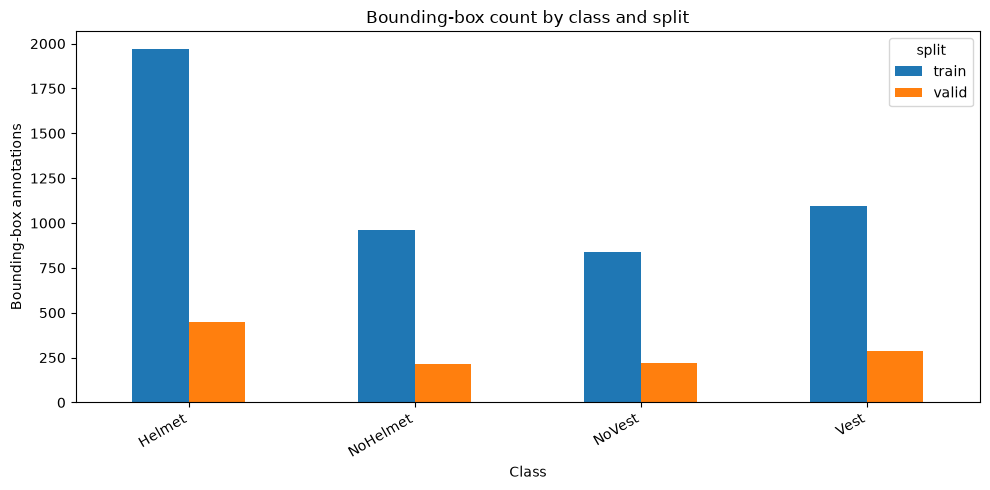

In [35]:
if not class_counts.empty:
    pivot = class_counts.pivot(index="class_name", columns="split", values="bounding_boxes").fillna(0)
    ax = pivot.plot(kind="bar", figsize=(10, 5))
    ax.set_title("Bounding-box count by class and split")
    ax.set_xlabel("Class")
    ax.set_ylabel("Bounding-box annotations")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No annotations found to plot.")

## 6. Inspect sample images with bounding boxes

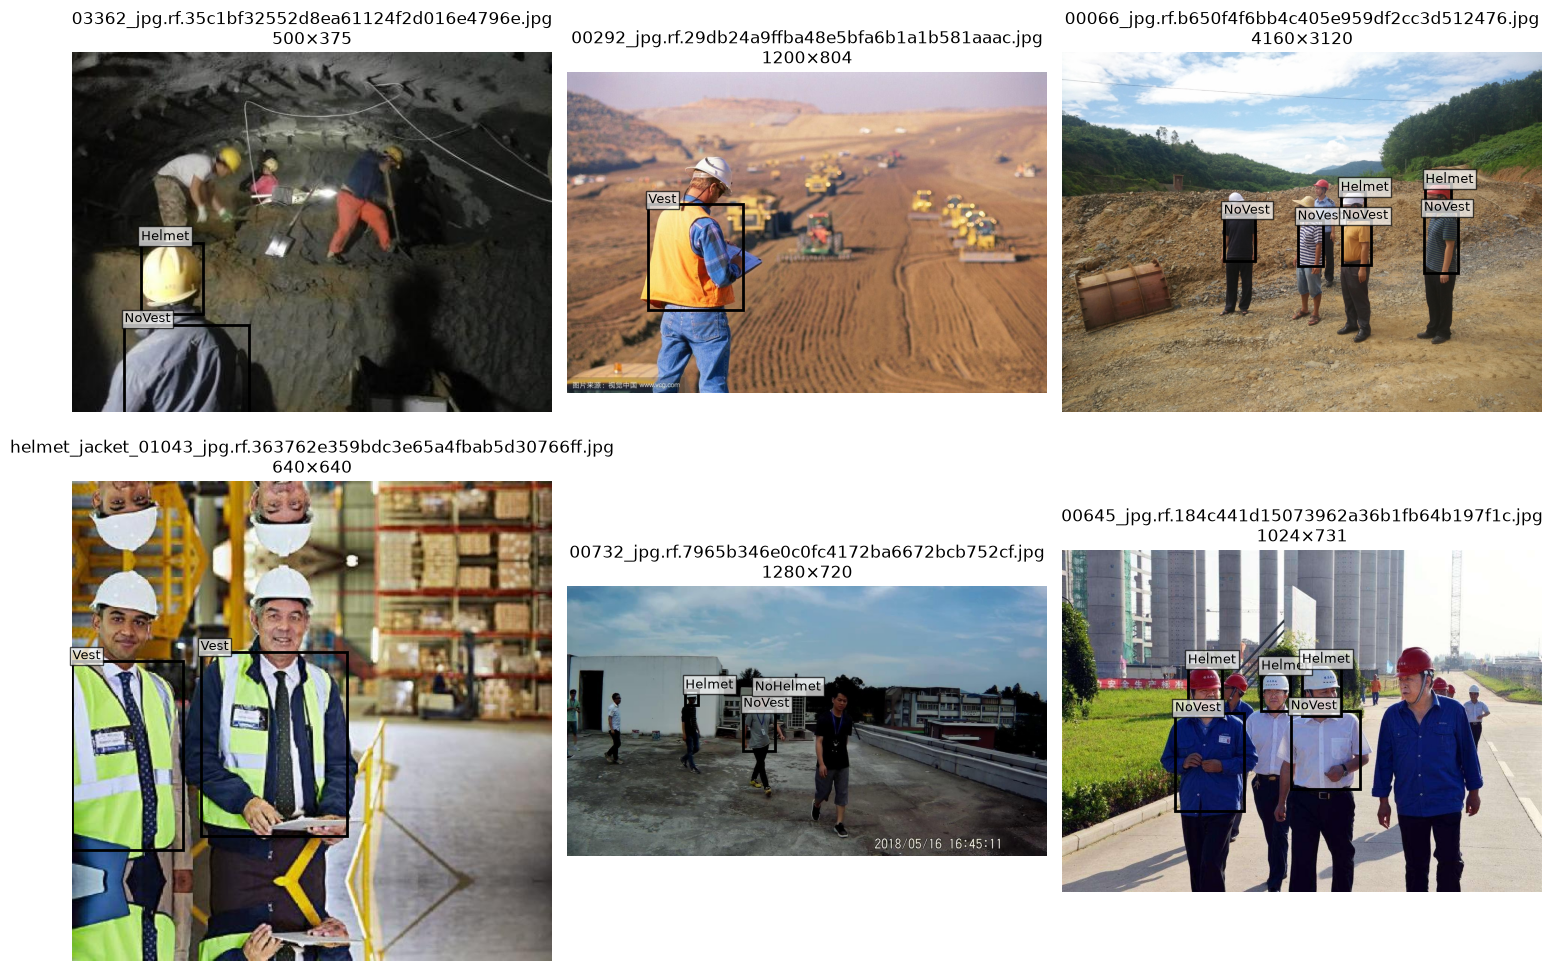

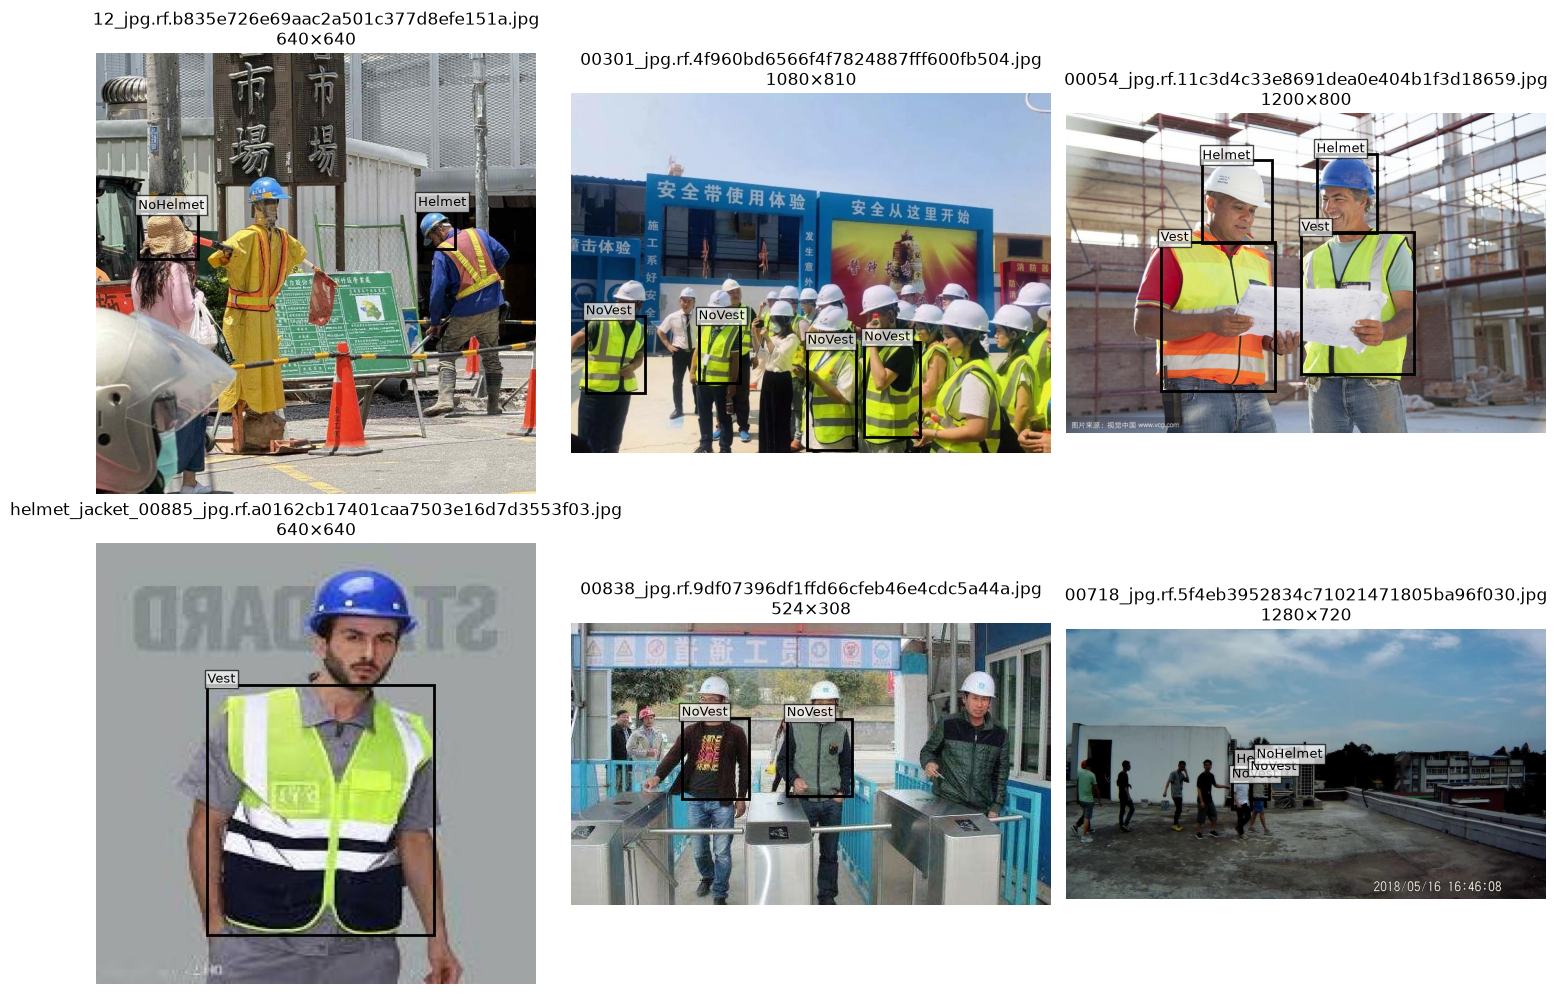

In [36]:
# Uses matplotlib to draw YOLO boxes. This is a visual spot-check, not a proof that labels are semantically correct.
from matplotlib.patches import Rectangle

def show_samples(split="train", n=6, seed=42):
    images = split_files.get(split, {}).get("images", [])
    if not images:
        print(f"No images found for split: {split}")
        return

    rng = random.Random(seed)
    chosen = rng.sample(images, min(n, len(images)))
    cols = 3
    rows = math.ceil(len(chosen) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
    axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

    for ax, image_path in zip(axes, chosen):
        try:
            image = Image.open(image_path).convert("RGB")
            w_img, h_img = image.size
            ax.imshow(image)
            label_path = split_files[split]["label_dir"] / f"{image_path.stem}.txt"
            if label_path.exists():
                for line in label_path.read_text(encoding="utf-8-sig").splitlines():
                    parts = line.split()
                    if len(parts) != 5:
                        continue
                    class_id = int(parts[0])
                    xc, yc, bw, bh = map(float, parts[1:])
                    x = (xc - bw / 2) * w_img
                    y = (yc - bh / 2) * h_img
                    rect = Rectangle((x, y), bw * w_img, bh * h_img,
                                     fill=False, linewidth=2)
                    ax.add_patch(rect)
                    label = CLASS_NAMES.get(class_id, f"Unknown {class_id}")
                    ax.text(x, max(0, y - 3), label, fontsize=9,
                            bbox={"facecolor": "white", "alpha": 0.7, "pad": 2})
            ax.set_title(f"{image_path.name}\n{w_img}×{h_img}")
            ax.axis("off")
        except Exception as exc:
            ax.set_title(f"Could not read {image_path.name}: {exc}")
            ax.axis("off")

    for ax in axes[len(chosen):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_samples("train", n=6)
show_samples("valid", n=6)

## 7. Image dimensions and file checks

In [37]:
dimension_rows = []
unreadable_images = []

for split in ["train", "valid", "test"]:
    for image_path in split_files[split]["images"]:
        try:
            with Image.open(image_path) as img:
                width, height = img.size
                dimension_rows.append({
                    "split": split, "file": image_path.name,
                    "width": width, "height": height,
                    "format": img.format, "mode": img.mode
                })
        except Exception as exc:
            unreadable_images.append({
                "split": split, "file": image_path.name, "problem": str(exc)
            })

dimensions_df = pd.DataFrame(dimension_rows)
if not dimensions_df.empty:
    display(dimensions_df.groupby("split")[["width", "height"]].describe())
    display(dimensions_df.groupby(["split", "width", "height"]).size().reset_index(name="images").head(30))
print("Unreadable images:", len(unreadable_images))
display(pd.DataFrame(unreadable_images).head(20) if unreadable_images else pd.DataFrame({"status": ["All scanned images opened successfully"]}))

width                                                               \
        count        mean         std    min    25%    50%     75%     max   
split                                                                        
train  1829.0  817.451066  543.886928  128.0  550.0  640.0  1010.0  5712.0   
valid   457.0  805.231947  556.676525  128.0  535.0  640.0   962.0  4080.0   

       height                                                              
        count        mean         std    min    25%    50%    75%     max  
split                                                                      
train  1829.0  635.412247  422.779209  139.0  381.0  640.0  720.0  4284.0  
valid   457.0  632.286652  433.004607  136.0  372.0  640.0  711.0  4032.0

,split,width,height,images
0,train,128,252,1
1,train,146,220,1
2,train,148,216,2
3,train,155,207,5
4,train,160,316,1
5,train,174,290,1
6,train,179,282,1
7,train,180,180,2
8,train,186,270,1
9,train,194,259,3


Unreadable images: 0


,status
0,All scanned images opened successfully


## 8. Dataset findings and readiness checklist

In [38]:
print("DATASET SUMMARY")
print("=" * 50)
print("Dataset root:", DATASET_ROOT.resolve())
print("Classes:", CLASS_NAMES)
display(counts_df)

print("\nReview these before training:")
print("1. Confirm class counts are not severely imbalanced.")
print("2. Inspect sample images above to confirm boxes cover the intended PPE objects.")
print("3. Review invalid annotations, empty labels, and image/label filename mismatches.")
print("4. Check for near-duplicate or overlapping images between train and validation if possible.")
print("5. This dataset defines Helmet, NoHelmet, NoVest, Vest only; it does not directly cover Gloves or Shoes.")
print("6. This notebook does not train a model. Training comes later, after project files and tests are ready.")

DATASET SUMMARY
Dataset root: C:\Users\morab\Desktop\PPE_Safety_Detection\data\raw\ppe_dataset
Classes: {0: 'Helmet', 1: 'NoHelmet', 2: 'NoVest', 3: 'Vest'}


,split,images,label_files,images_without_label_file,label_files_without_image
0,train,1829,1829,0,0
1,valid,457,457,0,0
2,test,0,0,0,0



Review these before training:
1. Confirm class counts are not severely imbalanced.
2. Inspect sample images above to confirm boxes cover the intended PPE objects.
3. Review invalid annotations, empty labels, and image/label filename mismatches.
4. Check for near-duplicate or overlapping images between train and validation if possible.
5. This dataset defines Helmet, NoHelmet, NoVest, Vest only; it does not directly cover Gloves or Shoes.
6. This notebook does not train a model. Training comes later, after project files and tests are ready.


In [40]:

# 1. Check dataset folders and image-label matching

from pathlib import Path

for split in ["train", "valid", "test"]:
    image_dir = DATASET_ROOT / split / "images"
    label_dir = DATASET_ROOT / split / "labels"

    print(f"\n--- {split.upper()} ---")

    if not image_dir.exists() or not label_dir.exists():
        print("Image or label folder is missing.")
        continue

    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]
    labels = list(label_dir.glob("*.txt"))

    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}

    print("Images:", len(images))
    print("Label files:", len(labels))
    print("Images without labels:", len(image_stems - label_stems))
    print("Labels without images:", len(label_stems - image_stems))

    if image_stems == label_stems:
        print("PASS: Image and label filenames match.")
    else:
        print("CHECK: Some image and label filenames do not match.")



--- TRAIN ---
Images: 1829
Label files: 1829
Images without labels: 0
Labels without images: 0
PASS: Image and label filenames match.

--- VALID ---
Images: 457
Label files: 457
Images without labels: 0
Labels without images: 0
PASS: Image and label filenames match.

--- TEST ---
Image or label folder is missing.


In [41]:

# 2. Check whether all dataset images can be opened

from PIL import Image

unreadable = []

for split in ["train", "valid", "test"]:
    image_dir = DATASET_ROOT / split / "images"

    if not image_dir.exists():
        continue

    for image_path in image_dir.iterdir():
        if image_path.suffix.lower() not in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }:
            continue

        try:
            with Image.open(image_path) as img:
                img.verify()
        except Exception as error:
            unreadable.append({
                "split": split,
                "file": image_path.name,
                "error": str(error)
            })

print("Unreadable images:", len(unreadable))

if unreadable:
    display(pd.DataFrame(unreadable))
else:
    print("PASS: All scanned images opened successfully.")


Unreadable images: 0
PASS: All scanned images opened successfully.


In [42]:

# 3. Check bounding-box counts for each class

print("Bounding boxes per class and split:")

display(
    class_counts.sort_values(
        by=["class_name", "split"]
    ).reset_index(drop=True)
)


Bounding boxes per class and split:


,split,class_id,class_name,bounding_boxes
0,train,0,Helmet,1970
1,valid,0,Helmet,451
2,train,1,NoHelmet,960
3,valid,1,NoHelmet,214
4,train,2,NoVest,836
5,valid,2,NoVest,222
6,train,3,Vest,1096
7,valid,3,Vest,289


In [43]:

# Check the current project folder structure

from pathlib import Path

project_root = Path(r"C:\Users\morab\Desktop\PPE_Safety_Detection")

for folder in [
    "data",
    "notebooks",
    "backend",
    "frontend",
    "models"
]:
    path = project_root / folder
    print(f"{folder}: {'EXISTS' if path.exists() else 'NOT CREATED'}")


data: EXISTS
notebooks: EXISTS
backend: EXISTS
frontend: EXISTS
models: NOT CREATED


In [44]:

# Check existing backend and frontend files

from pathlib import Path

PROJECT_ROOT = Path(
    r"C:\Users\morab\Desktop\PPE_Safety_Detection"
)

for folder_name in ["backend", "frontend", "models"]:
    folder_path = PROJECT_ROOT / folder_name

    print(f"\n--- {folder_name.upper()} ---")

    if not folder_path.exists():
        print("Folder not created")
        continue

    files = list(folder_path.rglob("*"))

    if not files:
        print("Folder is empty")
    else:
        for file_path in files:
            if file_path.is_file():
                print(file_path.relative_to(PROJECT_ROOT))



--- BACKEND ---
backend\app.py
backend\compliance.py
backend\config.py
backend\detector.py
backend\requirements.txt
backend\video_processor.py

--- FRONTEND ---
frontend\index.html
frontend\script.js
frontend\style.css

--- MODELS ---
Folder not created
